Train shape: (19992, 27) | Test shape: (4998, 27)
Urutan kelas: ['Normal', 'DoS', 'Probe', 'R2L', 'U2R']
=== Melatih Decision Tree ===
Fitting 5 folds for each of 12 candidates, totalling 60 fits


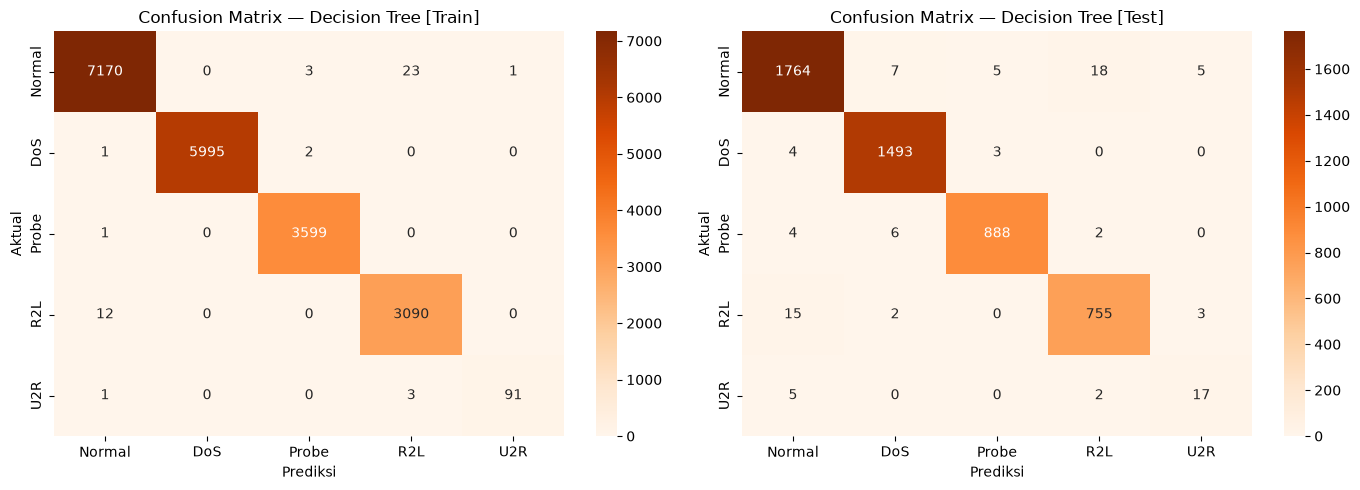


[Decision Tree] Test Accuracy: 0.9838 | Test Macro-F1: 0.9262 | ROC-AUC: 0.9617
[Decision Tree] Overfit Gap (Macro-F1): 0.0665 | Train Time: 9.43s | Predict Time: 0.0519s
              precision    recall  f1-score   support

      Normal     0.9844    0.9805    0.9825      1799
         DoS     0.9901    0.9953    0.9927      1500
       Probe     0.9911    0.9867    0.9889       900
         R2L     0.9717    0.9742    0.9729       775
         U2R     0.6800    0.7083    0.6939        24

    accuracy                         0.9838      4998
   macro avg     0.9234    0.9290    0.9262      4998
weighted avg     0.9839    0.9838    0.9838      4998

=== Melatih Extra Trees ===
Fitting 5 folds for each of 8 candidates, totalling 40 fits


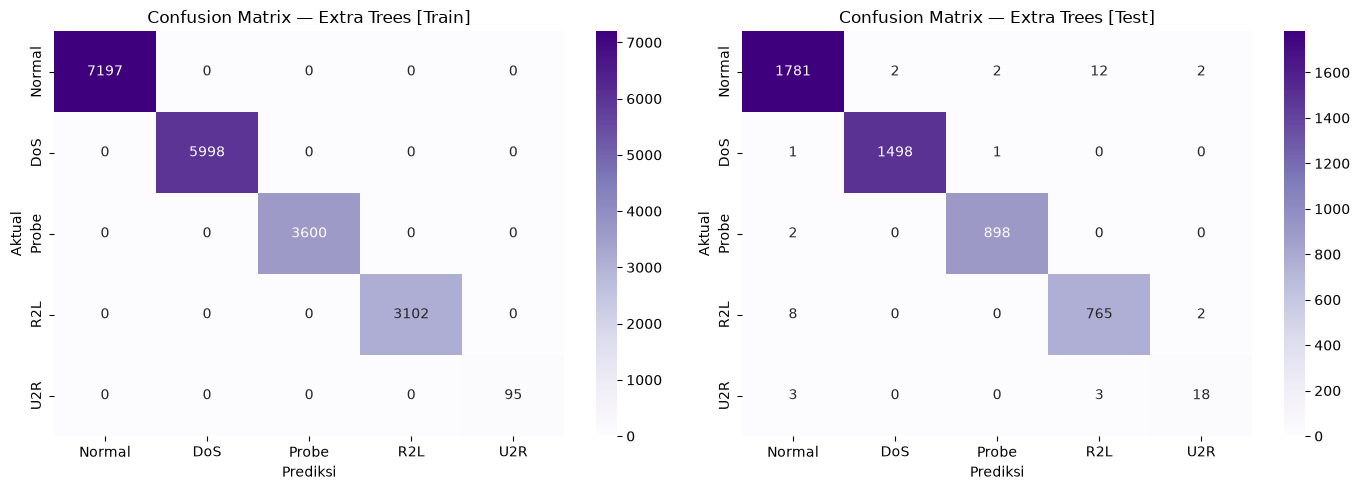


[Extra Trees] Test Accuracy: 0.9924 | Test Macro-F1: 0.9507 | ROC-AUC: 0.9995
[Extra Trees] Overfit Gap (Macro-F1): 0.0493 | Train Time: 44.85s | Predict Time: 0.2651s
              precision    recall  f1-score   support

      Normal     0.9922    0.9900    0.9911      1799
         DoS     0.9987    0.9987    0.9987      1500
       Probe     0.9967    0.9978    0.9972       900
         R2L     0.9808    0.9871    0.9839       775
         U2R     0.8182    0.7500    0.7826        24

    accuracy                         0.9924      4998
   macro avg     0.9573    0.9447    0.9507      4998
weighted avg     0.9923    0.9924    0.9924      4998

=== Melatih XGBoost ===
Fitting 5 folds for each of 8 candidates, totalling 40 fits


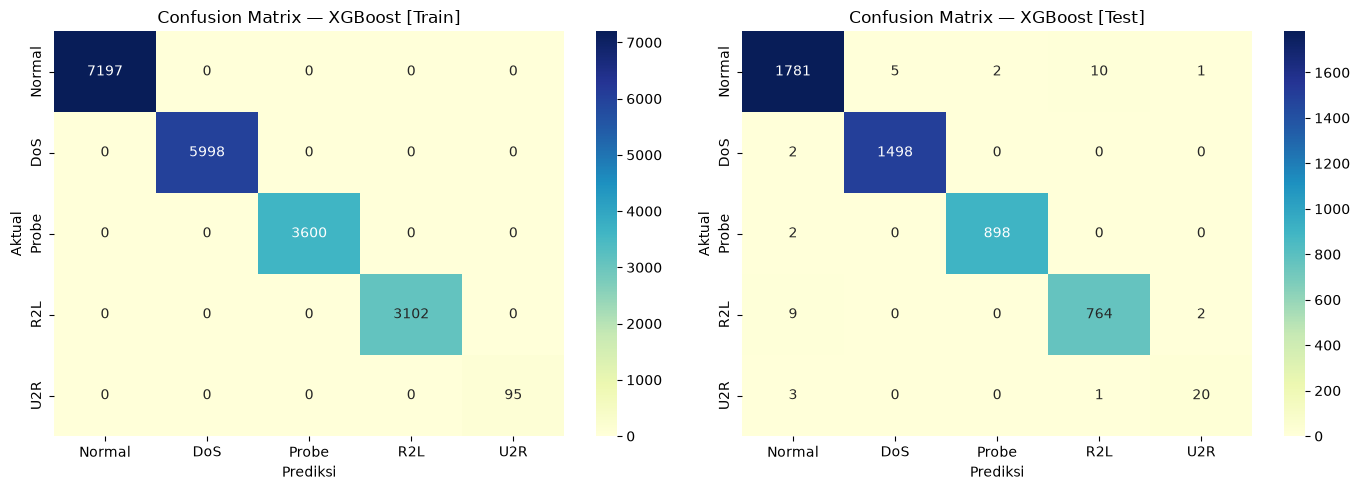


[XGBoost] Test Accuracy: 0.9926 | Test Macro-F1: 0.9646 | ROC-AUC: 0.9997
[XGBoost] Overfit Gap (Macro-F1): 0.0354 | Train Time: 39.02s | Predict Time: 0.3872s
              precision    recall  f1-score   support

      Normal     0.9911    0.9900    0.9905      1799
         DoS     0.9967    0.9987    0.9977      1500
       Probe     0.9978    0.9978    0.9978       900
         R2L     0.9858    0.9858    0.9858       775
         U2R     0.8696    0.8333    0.8511        24

    accuracy                         0.9926      4998
   macro avg     0.9682    0.9611    0.9646      4998
weighted avg     0.9926    0.9926    0.9926      4998



In [2]:
import json
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, LabelEncoder, OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")

# 1. Konfigurasi Path & Load Split Beku A2
PROJECT_ROOT = Path("..").resolve() if Path.cwd().name == "notebooks" else Path(".").resolve()
processed_dir = PROJECT_ROOT / "data" / "processed"
models_dir = PROJECT_ROOT / "models"
results_dir = PROJECT_ROOT / "results"
models_dir.mkdir(parents=True, exist_ok=True)
results_dir.mkdir(parents=True, exist_ok=True)

with open(processed_dir / "split_config.json", "r", encoding="utf-8") as f:
    split_cfg = json.load(f)

RANDOM_STATE = split_cfg["random_state"]  # 42
URUTAN_KELAS = split_cfg["urutan_kelas"]  # ["Normal", "DoS", "Probe", "R2L", "U2R"]
SORTED_KELAS = sorted(URUTAN_KELAS)       # ["DoS", "Normal", "Probe", "R2L", "U2R"] khusus roc_auc_score
SELECTED_FEATURES = split_cfg["selected_features"]
TARGET_COL = "kategori"

train_df = pd.read_csv(processed_dir / "train_split_80_20.csv")
test_df = pd.read_csv(processed_dir / "test_split_80_20.csv")

X_train = train_df[SELECTED_FEATURES].copy()
y_train = train_df[TARGET_COL].copy()
X_test = test_df[SELECTED_FEATURES].copy()
y_test = test_df[TARGET_COL].copy()

print(f"Train shape: {X_train.shape} | Test shape: {X_test.shape}")
print("Urutan kelas:", URUTAN_KELAS)

# 2. Preprocessor untuk Model Berbasis Pohon (Tanpa Scaling)
cat_cols = [c for c in ["protocol_type", "service", "flag"] if c in SELECTED_FEATURES]
log_cols = [c for c in ["duration", "src_bytes", "dst_bytes"] if c in SELECTED_FEATURES]
num_cols = [c for c in SELECTED_FEATURES if c not in cat_cols and c not in log_cols]

def buat_preprocessor_tree():
    return ColumnTransformer(
        transformers=[
            ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
            ("log", FunctionTransformer(np.log1p, validate=False), log_cols),
            ("num", "passthrough", num_cols),
        ],
        remainder="drop",
    )

# 3. Fungsi Evaluasi & Simpan Output Standar
def evaluasi_dan_simpan(
    model_key: str,
    model_name: str,
    estimator,
    best_params: dict,
    cv_macro_f1: float,
    train_time_s: float,
    cmap: str = "Blues",
):
    t_pred0 = time.time()
    y_pred_train = estimator.predict(X_train)
    y_pred_test = estimator.predict(X_test)
    pred_time_test_s = round(time.time() - t_pred0, 4)

    # Probabilitas sesuai urutan abjad (SORTED_KELAS) untuk roc_auc_score
    idx_sorted = [list(estimator.classes_).index(c) for c in SORTED_KELAS]
    y_prob_train_sorted = estimator.predict_proba(X_train)[:, idx_sorted]
    y_prob_test_sorted = estimator.predict_proba(X_test)[:, idx_sorted]

    def blok_metrik(y_true, y_pred, y_prob_sorted):
        cm = confusion_matrix(y_true, y_pred, labels=URUTAN_KELAS)
        rep = classification_report(
            y_true, y_pred, labels=URUTAN_KELAS, output_dict=True, zero_division=0
        )
        roc_ovr = float(
            roc_auc_score(y_true, y_prob_sorted, multi_class="ovr", average="macro", labels=SORTED_KELAS)
        )
        attack_classes = ["DoS", "Probe", "R2L", "U2R"]
        attack_recall_macro = float(np.mean([rep[c]["recall"] for c in attack_classes]))
        return {
            "accuracy": float(accuracy_score(y_true, y_pred)),
            "macro_f1": float(f1_score(y_true, y_pred, labels=URUTAN_KELAS, average="macro", zero_division=0)),
            "roc_auc_ovr": roc_ovr,
            "attack_recall_macro": attack_recall_macro,
            "classification_report": rep,
            "confusion_matrix": cm.tolist(),
        }, cm

    train_blk, cm_train = blok_metrik(y_train, y_pred_train, y_prob_train_sorted)
    test_blk, cm_test = blok_metrik(y_test, y_pred_test, y_prob_test_sorted)

    overfit_gap_f1 = round(train_blk["macro_f1"] - test_blk["macro_f1"], 6)
    overfit_gap_acc = round(train_blk["accuracy"] - test_blk["accuracy"], 6)

    joblib.dump(estimator, models_dir / f"{model_key}.joblib", compress=3)

    metrics_payload = {
        "model_name": model_name,
        "target": TARGET_COL,
        "classes": URUTAN_KELAS,
        "best_params": best_params,
        "train": train_blk,
        "test": test_blk,
        "cv_macro_f1": float(cv_macro_f1),
        "overfit_gap_macro_f1": overfit_gap_f1,
        "overfit_gap_accuracy": overfit_gap_acc,
        "train_time_s": float(train_time_s),
        "predict_time_s": float(pred_time_test_s),
    }

    with open(results_dir / f"metrics_{model_key}.json", "w", encoding="utf-8") as f:
        json.dump(metrics_payload, f, indent=2)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for ax, cm, judul in [
        (axes[0], cm_train, f"Confusion Matrix — {model_name} [Train]"),
        (axes[1], cm_test, f"Confusion Matrix — {model_name} [Test]"),
    ]:
        sns.heatmap(
            cm, annot=True, fmt="d", cmap=cmap,
            xticklabels=URUTAN_KELAS, yticklabels=URUTAN_KELAS, ax=ax
        )
        ax.set_title(judul)
        ax.set_xlabel("Prediksi")
        ax.set_ylabel("Aktual")
    plt.tight_layout()
    plt.savefig(results_dir / f"cm_{model_key}_train_test.png", dpi=150)
    plt.show()

    print(f"\n[{model_name}] Test Accuracy: {test_blk['accuracy']:.4f} | Test Macro-F1: {test_blk['macro_f1']:.4f} | ROC-AUC: {test_blk['roc_auc_ovr']:.4f}")
    print(f"[{model_name}] Overfit Gap (Macro-F1): {overfit_gap_f1:.4f} | Train Time: {train_time_s:.2f}s | Predict Time: {pred_time_test_s:.4f}s")
    print(classification_report(y_test, y_pred_test, labels=URUTAN_KELAS, digits=4, zero_division=0))
    return metrics_payload

cv_5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# MODEL 1: DECISION TREE
print("=== Melatih Decision Tree ===")
dt_pipe = Pipeline([
    ("prep", buat_preprocessor_tree()),
    ("clf", DecisionTreeClassifier(random_state=RANDOM_STATE)),
])
param_grid_dt = {
    "clf__max_depth": [10, 15, 20, None],
    "clf__min_samples_leaf": [1, 2, 5],
}
search_dt = GridSearchCV(dt_pipe, param_grid_dt, scoring="f1_macro", cv=cv_5, n_jobs=-1, verbose=1)
t0 = time.time()
search_dt.fit(X_train, y_train)
dt_time = round(time.time() - t0, 4)

res_dt = evaluasi_dan_simpan(
    "decision_tree", "Decision Tree", search_dt.best_estimator_,
    search_dt.best_params_, search_dt.best_score_, dt_time, cmap="Oranges"
)

# MODEL 2: EXTRA TREES
print("=== Melatih Extra Trees ===")
et_pipe = Pipeline([
    ("prep", buat_preprocessor_tree()),
    ("clf", ExtraTreesClassifier(random_state=RANDOM_STATE, n_jobs=-1)),
])
param_dist_et = {
    "clf__n_estimators": [100, 200, 300],
    "clf__max_depth": [None, 25, 35],
    "clf__min_samples_leaf": [1, 2],
}
search_et = RandomizedSearchCV(
    et_pipe, param_dist_et, n_iter=8, scoring="f1_macro",
    cv=cv_5, random_state=RANDOM_STATE, n_jobs=-1, verbose=1
)
t0 = time.time()
search_et.fit(X_train, y_train)
et_time = round(time.time() - t0, 4)

res_et = evaluasi_dan_simpan(
    "extra_trees", "Extra Trees", search_et.best_estimator_,
    search_et.best_params_, search_et.best_score_, et_time, cmap="Purples"
)

# MODEL 3: XGBOOST
print("=== Melatih XGBoost ===")
class StringXGBClassifier(BaseEstimator, ClassifierMixin):
    def __init__(self, n_estimators=200, max_depth=6, learning_rate=0.1, random_state=42):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.learning_rate = learning_rate
        self.random_state = random_state

    def fit(self, X, y):
        self.le_ = LabelEncoder()
        self.le_.fit(URUTAN_KELAS)
        y_enc = self.le_.transform(y)
        self.classes_ = self.le_.classes_
        self.model_ = XGBClassifier(
            n_estimators=self.n_estimators,
            max_depth=self.max_depth,
            learning_rate=self.learning_rate,
            random_state=self.random_state,
            eval_metric="mlogloss",
            n_jobs=-1,
        )
        self.model_.fit(X, y_enc)
        return self

    def predict(self, X):
        preds = self.model_.predict(X)
        return self.le_.inverse_transform(preds)

    def predict_proba(self, X):
        return self.model_.predict_proba(X)

    @property
    def feature_importances_(self):
        return self.model_.feature_importances_

xgb_pipe = Pipeline([
    ("prep", buat_preprocessor_tree()),
    ("clf", StringXGBClassifier(random_state=RANDOM_STATE)),
])
param_dist_xgb = {
    "clf__n_estimators": [150, 250, 350],
    "clf__max_depth": [4, 6, 8],
    "clf__learning_rate": [0.05, 0.1, 0.2],
}
search_xgb = RandomizedSearchCV(
    xgb_pipe, param_dist_xgb, n_iter=8, scoring="f1_macro",
    cv=cv_5, random_state=RANDOM_STATE, n_jobs=-1, verbose=1
)
t0 = time.time()
search_xgb.fit(X_train, y_train)
xgb_time = round(time.time() - t0, 4)

res_xgb = evaluasi_dan_simpan(
    "xgboost", "XGBoost", search_xgb.best_estimator_,
    search_xgb.best_params_, search_xgb.best_score_, xgb_time, cmap="YlGnBu"
)